# RA: 24011150  

In [ ]:
import seaborn as sns
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time
import kagglehub

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)
df = pd.read_csv("creditcard.csv")



## a
- Contexto do problema:
    O problema retrata a necessidade de implementação de um método para sistemas bancários diferenciarem transações fraudulentas de transações regulares.
- Descrição das variáveis:
    - Time: Tempo entre x transação e a primeira transação no dataset (algo como EPOCH timestamp)
    - V1 até V28: Features obtidas com aplicação de PCA
    - Amount: Quantidade de dinheiro movimentado na transação
    - Class: Variável binária para indicar se a transação é fraudulenta ou não (1 para fraudulenta, 0 para não fraudulenta)
- Desbalanceamento de classes:


## b

In [353]:
df.sample(15)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
279261,168743.0,-0.479974,-0.232187,0.549038,-1.890822,0.847631,-0.315065,0.120311,-0.016978,-1.806797,...,0.484109,1.130477,-0.294004,0.344592,0.266228,0.026293,0.066612,0.120913,26.57,0
224556,143858.0,2.124481,-1.783456,-0.977561,-1.492830,-1.453856,-0.448449,-1.235612,-0.049568,-0.854825,...,-0.130383,-0.149727,0.235809,0.609896,-0.330416,-0.208758,-0.007786,-0.029401,100.30,0
165675,117590.0,-1.010515,0.509023,-1.743334,-2.691105,2.793707,3.154727,0.431982,0.660170,1.266139,...,-0.142268,-0.147197,0.008459,0.677438,-0.523591,-1.267280,0.106102,0.490316,43.26,0
200634,133512.0,2.112041,0.015684,-2.535777,0.351841,0.732905,-1.336886,0.789062,-0.394525,-0.064764,...,0.272573,0.830769,-0.223061,-0.362274,0.629044,0.734094,-0.143368,-0.110503,10.00,0
198068,132314.0,0.019931,0.048554,-0.258679,-2.464019,0.313732,-0.726386,0.411317,0.013073,-1.088638,...,0.591283,1.635804,-0.073938,0.712852,-0.781714,-0.254091,0.440486,0.298238,15.00,0
125203,77569.0,0.936902,-0.445531,-0.420875,-0.002460,-0.004812,-0.131034,0.265664,0.065841,-0.240824,...,0.125029,0.057986,-0.138389,-0.219465,0.282290,1.102086,-0.117379,-0.005695,139.00,0
32620,36885.0,-3.255070,-4.224195,2.623914,-0.549000,2.463084,-1.293465,-2.305848,0.528941,1.810754,...,0.342905,0.318271,0.591148,-0.229584,0.442502,0.156773,-0.195821,-0.076804,133.20,0
112158,72535.0,-0.362805,1.179092,1.442446,0.133700,-0.084053,-1.159333,0.752076,-0.123052,-0.494532,...,-0.236780,-0.587288,0.018056,0.674425,-0.187099,0.049966,0.249603,0.102653,2.69,0
11399,19888.0,1.323957,-0.578627,0.813067,-0.159066,-1.255824,-0.655713,-0.831532,-0.047951,1.060218,...,-0.131748,-0.078475,0.098618,0.525426,0.334387,-0.279771,-0.005826,0.004267,5.00,0
250746,155049.0,1.958210,-0.248525,-0.590238,1.426129,-0.146467,0.193935,-0.372575,0.146120,1.368279,...,-0.562113,-1.422235,0.447209,0.354498,-0.300885,-1.118684,0.040864,-0.028188,11.35,0


## c

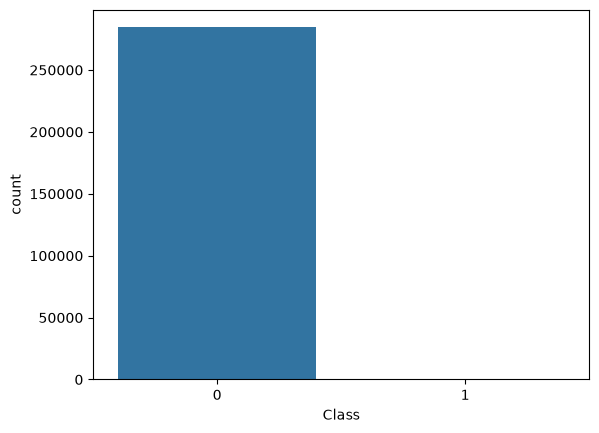

In [354]:
sns.countplot(x = 'Class', data= df)

plt.show()

## d

## d.a

## d.b

<Axes: xlabel='Class', ylabel='Count'>

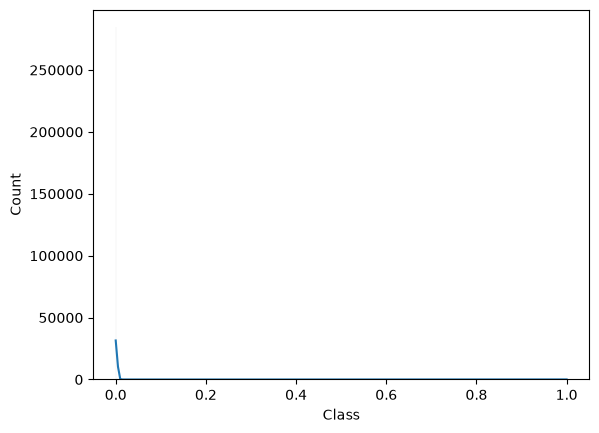

In [355]:
df_copy = df.copy()

df_copy["Time"] = pd.to_timedelta(df_copy['Time'])

df_copy.sample(15)

sns.histplot(data=df_copy, x="Class", kde = True)